定义逻辑回归模型函数

In [98]:
import numpy as np
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

class LogisticRegressionGD:
    def __init__(self, learning_rate=0.01, max_iter=1000, tol=1e-4, random_state=None):
        """
        初始化逻辑回归模型
        
        参数:
        - learning_rate: 学习率 (默认: 0.01)
        - max_iter: 最大迭代次数 (默认: 1000)
        - tol: 收敛阈值 (默认: 1e-4)
        - random_state: 随机种子 (默认: None)
        """
        self.learning_rate = learning_rate
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.weights = None
        self.bias = None
        self.train_loss_history = []
        self.train_acc_history = []
        self.test_loss_history = []
        self.test_acc_history = []
        
    def sigmoid(self, z):
        """Sigmoid函数"""
        return 1 / (1 + np.exp(-z))
    
    def compute_loss(self, y_true, y_pred):
        """计算对数损失"""
        epsilon = 1e-15  # 避免log(0)
        y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
        return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
    
    def fit(self, X_train, y_train, X_test=None, y_test=None, verbose=False, plot_interval=50):
        """
        训练逻辑回归模型
        
        参数:
        - X_train: 训练特征矩阵 (n_samples, n_features)
        - y_train: 训练目标向量 (n_samples,)
        - X_test: 测试特征矩阵 (可选)
        - y_test: 测试目标向量 (可选)
        - verbose: 是否打印训练过程 (默认: False)
        - plot_interval: 绘图间隔 (默认: 50次迭代记录一次)
        """
        np.random.seed(self.random_state)
        n_samples, n_features = X_train.shape
        
        # 初始化权重和偏置
        self.weights = np.random.randn(n_features)
        self.bias = 0
        
        # 清空历史记录
        self.train_loss_history = []
        self.train_acc_history = []
        self.test_loss_history = []
        self.test_acc_history = []
        
        for i in range(self.max_iter):
            # 线性组合
            linear_model = np.dot(X_train, self.weights) + self.bias
            # Sigmoid变换
            y_pred = self.sigmoid(linear_model)
            
            # 计算梯度
            dw = (1 / n_samples) * np.dot(X_train.T, (y_pred - y_train))
            db = (1 / n_samples) * np.sum(y_pred - y_train)
            
            # 更新参数
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
            
            # 每隔plot_interval次迭代记录一次
            if i % plot_interval == 0 or i == self.max_iter - 1:
                # 训练集评估
                train_loss = self.compute_loss(y_train, y_pred)
                train_acc = accuracy_score(y_train, (y_pred >= 0.5).astype(int))
                self.train_loss_history.append(train_loss)
                self.train_acc_history.append(train_acc)
                
                # 测试集评估（如果提供了测试集）
                if X_test is not None and y_test is not None:
                    test_pred = self.predict_proba(X_test)
                    test_loss = self.compute_loss(y_test, test_pred)
                    test_acc = accuracy_score(y_test, (test_pred >= 0.5).astype(int))
                    self.test_loss_history.append(test_loss)
                    self.test_acc_history.append(test_acc)
            
            # 打印训练过程
            if verbose and i % 100 == 0:
                print(f"Iteration {i}: Train Loss = {train_loss:.4f}, Train Acc = {train_acc:.4f}")
                if X_test is not None and y_test is not None:
                    print(f"           Test Loss = {test_loss:.4f}, Test Acc = {test_acc:.4f}")
            
            # 检查收敛
            if i > 0 and len(self.train_loss_history) > 1 and \
               abs(self.train_loss_history[-2] - self.train_loss_history[-1]) < self.tol:
                if verbose:
                    print(f"Converged at iteration {i}")
                break
                
        return self
    
    def predict_proba(self, X):
        """预测概率"""
        linear_model = np.dot(X, self.weights) + self.bias
        return self.sigmoid(linear_model)
    
    def predict(self, X, threshold=0.5):
        """预测类别"""
        proba = self.predict_proba(X)
        return (proba >= threshold).astype(int)
    
    def score(self, X, y):
        """计算准确率"""
        y_pred = self.predict(X)
        return accuracy_score(y, y_pred)



加载数据

In [99]:
def load_data(X_path, y_path):
    """加载数据"""
    X = pd.read_csv(X_path)
    y = pd.read_csv(y_path)
    
    # 确保X和y的行数匹配
    assert len(X) == len(y), "X和y的行数不匹配"
    
    # 提取特征和目标值
    X_values = X.values
    y_values = y.values.ravel()
    
    return X_values, y_values


可视化结果

In [100]:
def plot_learning_curves(train_loss, train_acc, test_loss=None, test_acc=None, 
                         plot_interval=50, title="Learning Curves"):
    """绘制学习曲线（损失和准确率）"""
    iterations = np.arange(0, len(train_loss) * plot_interval, plot_interval)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # 绘制训练损失曲线
    ax1.plot(iterations, train_loss, 'o-', label='Train Loss', color='tab:blue', markersize=5)
    if test_loss is not None:
        ax1.plot(iterations, test_loss, 'o-', label='Test Loss', color='tab:red', markersize=5)
    ax1.set_xlabel('Iteration')
    ax1.set_ylabel('Loss')
    ax1.set_title('Training & Test Loss')
    ax1.legend()
    ax1.grid(True)
    
    # 绘制准确率曲线
    ax2.plot(iterations, train_acc, 'o-', label='Train Accuracy', color='tab:orange', markersize=5)
    if test_acc is not None:
        ax2.plot(iterations, test_acc, 'o-', label='Test Accuracy', color='tab:green', markersize=5)
    ax2.set_xlabel('Iteration')
    ax2.set_ylabel('Accuracy')
    ax2.set_title('Training & Test Accuracy')
    ax2.legend()
    ax2.grid(True)
    
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

评估模型

In [101]:

def evaluate_model(model, X_train, y_train, X_test, y_test):
    """评估模型并绘制结果"""
    # 训练集评估
    train_pred = model.predict(X_train)
    train_acc = accuracy_score(y_train, train_pred)
    
    # 测试集评估
    test_pred = model.predict(X_test)
    test_acc = accuracy_score(y_test, test_pred)
    
    # 绘制学习曲线
    plot_learning_curves(
        model.train_loss_history, 
        model.train_acc_history,
        model.test_loss_history,
        model.test_acc_history,
        plot_interval=50,
        title="Training and Test Learning Curves"
    )
    
    return train_acc, test_acc

进行训练和预测


Training with learning rate: 5e-05


C:\Users\Administrator\AppData\Local\Temp\ipykernel_26896\2036853237.py:31: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))
C:\Users\Administrator\AppData\Local\Temp\ipykernel_26896\2036853237.py:31: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))
C:\Users\Administrator\AppData\Local\Temp\ipykernel_26896\2036853237.py:31: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))
C:\Users\Administrator\AppData\Local\Temp\ipykernel_26896\2036853237.py:31: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


Time taken to train the model:  1.2057981491088867


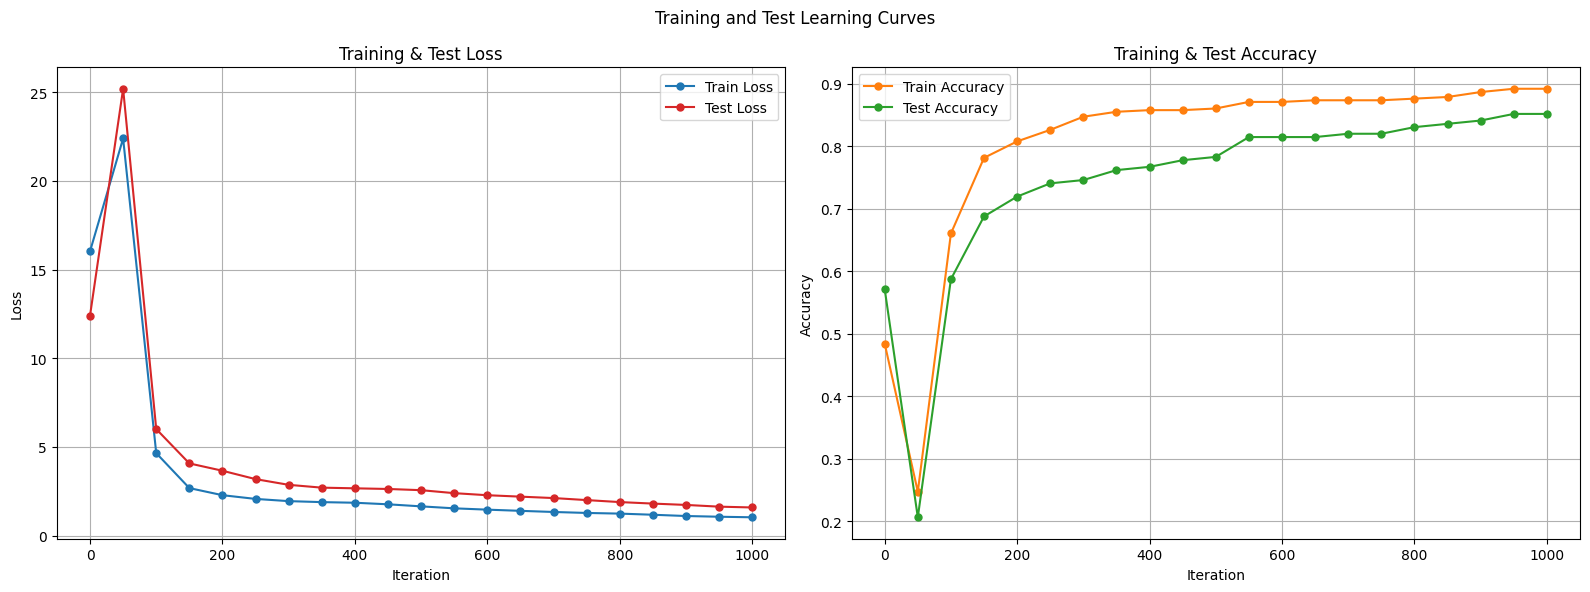


Final Results:
Learning Rate: 5e-05
Final Training Accuracy: 0.8921
Final Test Accuracy: 0.8519
Final Training Loss: 1.0313
Final Test Loss: 1.5855


In [102]:
def main():
    # 加载数据
    x_train, y_train = load_data('data/train/X_train.csv', 'data/train/Y_train.csv')
    x_test, y_test = load_data('data/test/X_test.csv', 'data/test/Y_test.csv')
    
    # 设置固定学习率
    learning_rate = 0.00005
    
    print(f"\nTraining with learning rate: {learning_rate}")
    model = LogisticRegressionGD(learning_rate=learning_rate, 
                                max_iter=10000, 
                                tol=1e-4, 
                                random_state=42)
    start = time.time()
    # 训练模型并记录测试集表现
    model.fit(x_train, y_train, x_test, y_test, verbose=False, plot_interval=500)
    end= time.time()
    print("Time taken to train the model: ", end-start)
    # 评估模型
    train_acc, test_acc = evaluate_model(model, x_train, y_train, x_test, y_test)
    
    # 打印最终结果
    print("\nFinal Results:")
    print(f"Learning Rate: {learning_rate}")
    print(f"Final Training Accuracy: {train_acc:.4f}")
    print(f"Final Test Accuracy: {test_acc:.4f}")
    print(f"Final Training Loss: {model.train_loss_history[-1]:.4f}")
    if model.test_loss_history:
        print(f"Final Test Loss: {model.test_loss_history[-1]:.4f}")

if __name__ == "__main__":
    main()